# 02 · Train the face-quality model (Đức Mạnh)

**Input:** `labels/` from `01_build_labels.ipynb` (24 000 crops, labels 0–1, split by identity).
**Model:** MobileNetV3-Small, ImageNet backbone **fine-tuned end to end** (partial transfer learning, not a
pre-trained model used as is) + a new regression head (256 → 1, sigmoid). Defined once in `infer.build_model()`, so the
app loads exactly this network.
**Loss:** Huber (smooth L1) on the label. **Selection:** best validation Spearman correlation.

Runs on Colab GPU (Runtime → GPU) or locally on CPU. On Colab, put this repo folder (or at least `ml/live_face_scan/`)
and `labels/` on Drive and set `REPO` / `LABELS` in the next cell.

In [1]:
import json, os, sys, time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

try:
    import google.colab  # noqa: F401
    from google.colab import drive
    drive.mount("/content/drive")
    REPO = Path("/content/drive/MyDrive/face_quality_colab/repo")     # folder made for Colab; edit if moved
    LABELS = Path("/content/drive/MyDrive/face_quality_colab/labels")
except ImportError:
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".agents").is_dir())
    LABELS = REPO / "data" / "raw" / "face_quality" / "labels"
sys.path.insert(0, str(REPO / "ml" / "live_face_scan"))
import infer as quality

SEED = 30082
EPOCHS = 12
BATCH = 128
LR_BACKBONE, LR_HEAD = 3e-4, 1e-3
WEIGHT_DECAY = 1e-4
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(max(1, os.cpu_count() or 1))
print("device:", device, "| torch", torch.__version__)

Mounted at /content/drive
device: cuda | torch 2.14.1+cu130


## 1. Data

In [2]:
import csv
images = np.load(LABELS / "images.npy")
rows = list(csv.DictReader((LABELS / "labels.csv").open(encoding="utf-8")))
meta = json.loads((LABELS / "meta.json").read_text(encoding="utf-8"))
y = np.array([float(r["label"]) for r in rows], np.float32)
split = np.array([r["split"] for r in rows])
tr, va = np.where(split == "train")[0], np.where(split == "val")[0]
assert not set(r["identity"] for r in np.array(rows)[tr]) & set(r["identity"] for r in np.array(rows)[va]), "identity leak"
print(f"train {len(tr)} crops / val {len(va)} crops (no identity in both) | recogniser {meta['recogniser_version']}")

MEAN = torch.tensor(quality.MEAN).view(1, 3, 1, 1); STD = torch.tensor(quality.STD).view(1, 3, 1, 1)

def to_tensor(idx, train):
    x = torch.from_numpy(np.ascontiguousarray(images[idx][..., ::-1])).permute(0, 3, 1, 2).float() / 255
    if train:                                   # only label-preserving augmentation: horizontal flip
        flip = torch.rand(len(idx)) < 0.5
        x[flip] = x[flip].flip(-1)
    x = nn.functional.interpolate(x, size=(quality.INPUT_SIZE, quality.INPUT_SIZE), mode="bilinear",
                                  align_corners=False, antialias=True)
    return ((x - MEAN) / STD).to(device), torch.from_numpy(y[idx]).to(device)

train 19200 crops / val 4800 crops (no identity in both) | recogniser v1


## 2. Model, optimiser

In [3]:
model = quality.build_model(pretrained=True).to(device)
head = list(model.classifier.parameters())
head_ids = {id(p) for p in head}
backbone = [p for p in model.parameters() if id(p) not in head_ids]
opt = torch.optim.AdamW([{"params": backbone, "lr": LR_BACKBONE}, {"params": head, "lr": LR_HEAD}],
                        weight_decay=WEIGHT_DECAY)
steps = EPOCHS * int(np.ceil(len(tr) / BATCH))
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[LR_BACKBONE, LR_HEAD], total_steps=steps, pct_start=0.15)
loss_fn = nn.HuberLoss(delta=0.1)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f} M parameters, all trainable; {steps} steps")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 59.7MB/s]


1.07 M parameters, all trainable; 1800 steps


## 3. Train

In [4]:
def spearman(a, b):
    ra, rb = np.argsort(np.argsort(a)), np.argsort(np.argsort(b))
    return float(np.corrcoef(ra, rb)[0, 1])

def predict(idx):
    model.eval(); out = []
    with torch.inference_mode():
        for i in range(0, len(idx), 512):
            out.append(model(to_tensor(idx[i:i + 512], False)[0])[:, 0].float().cpu().numpy())
    return np.concatenate(out)

history, best = [], (-1, None)
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train(); perm = np.random.permutation(tr); total = 0.0
    for i in range(0, len(perm), BATCH):
        x, t = to_tensor(perm[i:i + BATCH], True)
        loss = loss_fn(model(x)[:, 0], t)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        total += float(loss) * len(t)
    p = predict(va)
    h = dict(epoch=epoch, train_loss=total / len(tr), val_loss=float(loss_fn(torch.tensor(p), torch.tensor(y[va]))),
             val_mae=float(np.abs(p - y[va]).mean()), val_spearman=spearman(p, y[va]), seconds=time.time() - t0)
    history.append(h)
    if h["val_spearman"] > best[0]:
        best = (h["val_spearman"], {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, epoch)
    print(f"epoch {epoch:2d}  train {h['train_loss']:.4f}  val {h['val_loss']:.4f}  MAE {h['val_mae']:.3f}  "
          f"Spearman {h['val_spearman']:.3f}  ({h['seconds']:.0f} s)")
print(f"best epoch {best[2]}: val Spearman {best[0]:.3f}")

/tmp/ipykernel_515/3660855751.py:20: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  total += float(loss) * len(t)


epoch  1  train 0.0106  val 0.0099  MAE 0.141  Spearman 0.685  (35 s)
epoch  2  train 0.0079  val 0.0085  MAE 0.127  Spearman 0.728  (30 s)
epoch  3  train 0.0070  val 0.0081  MAE 0.123  Spearman 0.722  (29 s)
epoch  4  train 0.0062  val 0.0080  MAE 0.121  Spearman 0.724  (29 s)
epoch  5  train 0.0053  val 0.0082  MAE 0.124  Spearman 0.714  (29 s)
epoch  6  train 0.0045  val 0.0086  MAE 0.127  Spearman 0.714  (29 s)
epoch  7  train 0.0038  val 0.0086  MAE 0.127  Spearman 0.711  (29 s)
epoch  8  train 0.0032  val 0.0086  MAE 0.127  Spearman 0.718  (29 s)
epoch  9  train 0.0028  val 0.0085  MAE 0.127  Spearman 0.708  (30 s)
epoch 10  train 0.0025  val 0.0086  MAE 0.127  Spearman 0.709  (30 s)
epoch 11  train 0.0024  val 0.0086  MAE 0.127  Spearman 0.706  (30 s)
epoch 12  train 0.0022  val 0.0086  MAE 0.127  Spearman 0.707  (29 s)
best epoch 2: val Spearman 0.728


## 4. Learning curves and validation fit

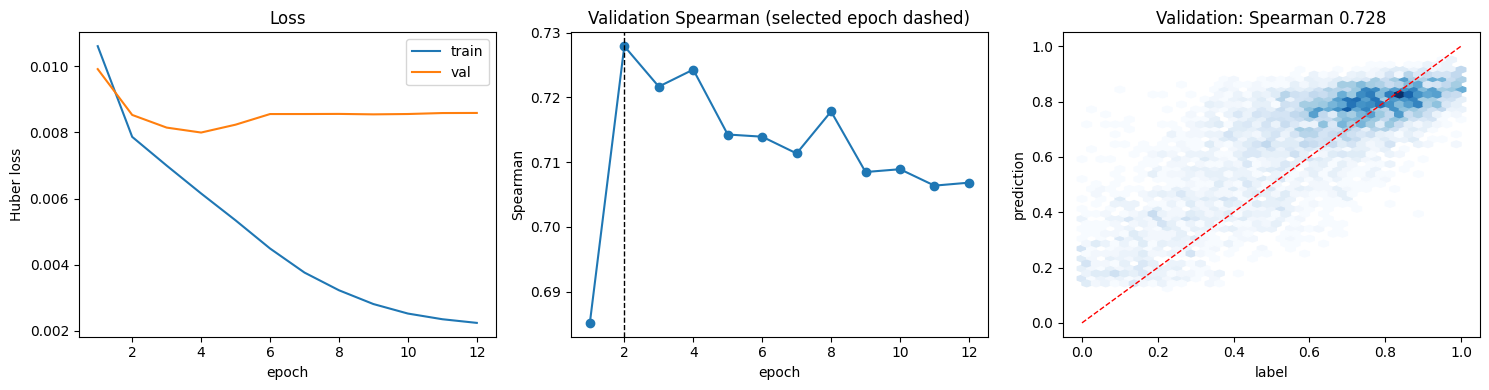

validation per damage type (mean label vs mean prediction):
  clean      label 0.773  prediction 0.811  Spearman +0.351
  blur       label 0.532  prediction 0.585  Spearman +0.733
  motion     label 0.419  prediction 0.497  Spearman +0.658
  noise      label 0.301  prediction 0.389  Spearman +0.710
  jpeg       label 0.600  prediction 0.717  Spearman +0.474
  downscale  label 0.642  prediction 0.689  Spearman +0.651
  dark       label 0.651  prediction 0.721  Spearman +0.517
  bright     label 0.472  prediction 0.540  Spearman +0.804
  occlusion  label 0.469  prediction 0.546  Spearman +0.622
  pose       label 0.659  prediction 0.690  Spearman +0.470


In [5]:
model.load_state_dict(best[1]); p = predict(va)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
e = [h["epoch"] for h in history]
ax[0].plot(e, [h["train_loss"] for h in history], label="train"); ax[0].plot(e, [h["val_loss"] for h in history], label="val")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("Huber loss"); ax[0].legend(); ax[0].set_title("Loss")
ax[1].plot(e, [h["val_spearman"] for h in history], marker="o"); ax[1].axvline(best[2], color="k", ls="--", lw=1)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("Spearman"); ax[1].set_title("Validation Spearman (selected epoch dashed)")
ax[2].hexbin(y[va], p, gridsize=40, cmap="Blues", mincnt=1); ax[2].plot([0, 1], [0, 1], "r--", lw=1)
ax[2].set_xlabel("label"); ax[2].set_ylabel("prediction"); ax[2].set_title(f"Validation: Spearman {spearman(p, y[va]):.3f}")
plt.tight_layout(); plt.show()

kinds = np.array([r["damage"] for r in rows])[va]
print("validation per damage type (mean label vs mean prediction):")
for k in ["clean", *meta["damages"]]:
    m = kinds == k
    print(f"  {k:10s} label {y[va][m].mean():.3f}  prediction {p[m].mean():.3f}  Spearman {spearman(p[m], y[va][m]):+.3f}")

## 5. Export `live_face_scan.pt`

The accept threshold is a placeholder here; `03_evaluate.ipynb` sets it from the EDC curve.

In [6]:
versions = json.loads((REPO / "ml/model_versions.json").read_text(encoding="utf-8"))
payload = dict(architecture="mobilenet_v3_small_quality", input_size=quality.INPUT_SIZE, color_space="RGB",
               normalization=dict(mean=list(quality.MEAN), std=list(quality.STD)), output="sigmoid 0..1",
               state_dict=best[1], threshold=0.5, threshold_status="placeholder until 03_evaluate.ipynb",
               recogniser="face_recognition", recogniser_version=meta["recogniser_version"],
               label_rule=meta["label_rule"], training=dict(seed=SEED, epochs=EPOCHS, batch=BATCH,
               lr_backbone=LR_BACKBONE, lr_head=LR_HEAD, weight_decay=WEIGHT_DECAY, loss="huber(0.1)",
               schedule="one-cycle", augmentation="horizontal flip", pretrained_backbone="ImageNet1K_V1",
               fine_tuned="all layers", best_epoch=best[2], device=str(device)),
               validation=dict(spearman=best[0], mae=float(np.abs(p - y[va]).mean())),
               history=history, data=dict(train_crops=int(len(tr)), val_crops=int(len(va)),
               identities=meta["identities"], val_identities=meta["val_identities"]))
out = REPO / "ml" / "live_face_scan" / "live_face_scan.pt"
torch.save(payload, out)
print(f"saved {out} ({out.stat().st_size / 1e6:.1f} MB)")
quality._state.clear()
print("check through infer.py:", round(quality.score(images[va[0]]), 4), "vs", round(float(p[0]), 4))

saved /content/drive/MyDrive/face_quality_colab/repo/ml/live_face_scan/live_face_scan.pt (4.4 MB)
check through infer.py: 0.8355 vs 0.8355
